In [1]:
#Ejercicio 1 Calcular la probabilidad de que al extraer tres cartas a la vez de una baraja de 48 salgan sota, caballo y rey:
#1.en ese orden.
  
#2.en cualquier orden.

# Punto 1: En ese orden exacto
p1 <- (4/48) * (4/47) * (4/46)
print(p1)

# Punto 2: Usando combinaciones (choose)
# choose(n, k) calcula combinaciones de n tomados de a k
favorables <- choose(4, 1) * choose(4, 1) * choose(4, 1) # 4*4*4 = 64
totales <- choose(48, 3)                                 # 17296
p2 <- favorables / totales
print(p2)


[1] 0.0006167129
[1] 0.003700278


In [1]:
#Ejercicio 2
# 1. Definir los datos de entrada
pA <- 0.60; pB <- 0.40; pC <- 0.30
pAB <- 0.20; pAC <- 0.10; pBC <- 0.20
pABC <- 0.05

# 2. Punto 1: Por lo menos a uno (Unión total via Inclusión-Exclusión)
p_al_menos_uno <- pA + pB + pC - pAB - pAC - pBC + pABC
cat("Punto 1 (Por lo menos uno):", p_al_menos_uno, "\n")

# 3. Punto 2: Exactamente a uno
solo_A <- pA - pAB - pAC + pABC
solo_B <- pB - pAB - pBC + pABC
solo_C <- pC - pAC - pBC + pABC

p_exactamente_uno <- solo_A + solo_B + solo_C
cat("Punto 2 (Solo A):", solo_A, "| (Solo B):", solo_B, "| (Solo C):", solo_C, "\n")
cat("Punto 2 (Total exactamente uno):", p_exactamente_uno, "\n")


Punto 1 (Por lo menos uno): 0.85 
Punto 2 (Solo A): 0.35 | (Solo B): 0.05 | (Solo C): 0.05 
Punto 2 (Total exactamente uno): 0.45 


In [2]:
#Ejercicio 3
#Enunciado: Tres corredores del equipo A y tres del equipo B participan en una carrera. Si los seis corredores tienen idéntica habilidad, ¿cuál es la probabilidad de que los tres corredores del equipo A lleguen en las tres primeras posiciones?
# 1. Cálculo exacto con permutaciones
favorables <- factorial(3) * factorial(3)
totales <- factorial(6)
p_exacta <- favorables / totales
cat("Probabilidad exacta (permutaciones):", p_exacta, "\n")

# 2. Cálculo exacto con combinaciones
p_comb <- 1 / choose(6, 3)
cat("Probabilidad exacta (combinaciones):", p_comb, "\n")

# 3. Simulación de Monte Carlo
N <- 100000
equipo <- c("A", "A", "A", "B", "B", "B")
exitos <- 0

set.seed(123)
for (i in 1:N) {
  llegada <- sample(equipo) # Orden aleatorio de llegada
  if (all(llegada[1:3] == "A")) {
    exitos <- exitos + 1
  }
}

cat("Probabilidad simulada:", exitos / N, "\n")


Probabilidad exacta (permutaciones): 0.05 
Probabilidad exacta (combinaciones): 0.05 
Probabilidad simulada: 0.0497 


Valor continuo de n: 24.6051 
Número mínimo de lanzamientos (n): 25 



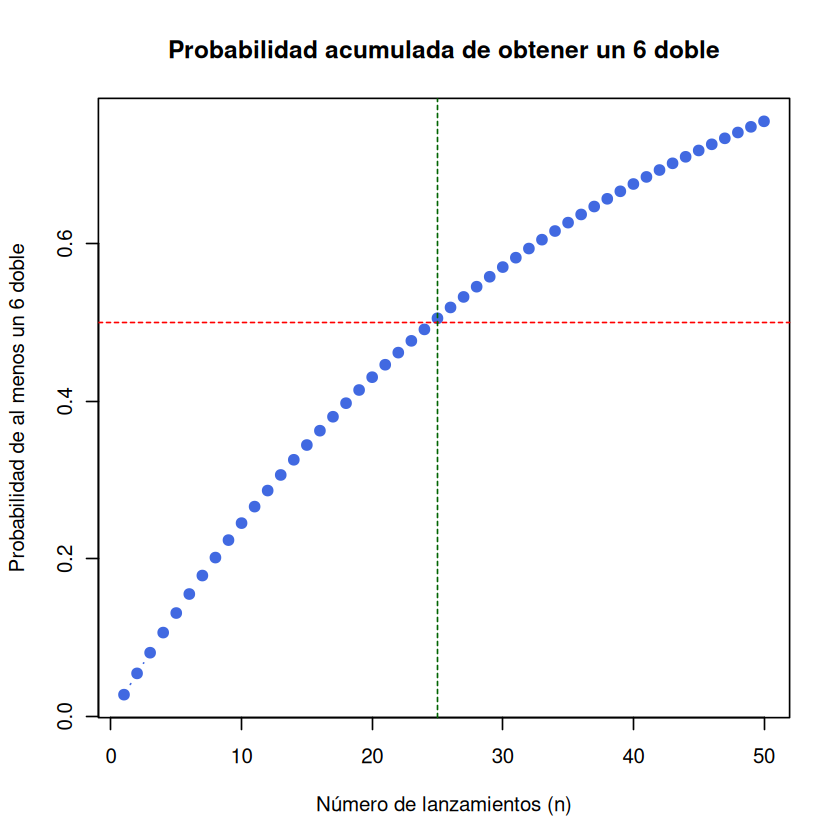

In [10]:
#Ejercicio 4
#Enunciado: Calcular la probabilidad de que al lanzar n veces dos dados se obtenga al menos un seis doble.
#¿Cuánto debiera ser n para que la probabilidad sea al menos 1/2?

# 1. Despeje analítico del n mínimo
n_exacto <- log(0.5) / log(35/36)
n_minimo <- ceiling(n_exacto) # Redondea hacia arriba al entero más cercano

cat("Valor continuo de n:", n_exacto, "\n")
cat("Número mínimo de lanzamientos (n):", n_minimo, "\n\n")

# 2. Construir una función de probabilidad para distintos n
prob_seis_doble <- function(n) {
  return(1 - (35/36)^n)
}

# 3. Graficar la evolución de la probabilidad de n = 1 a 50
n_valores <- 1:50
p_valores <- prob_seis_doble(n_valores)

plot(n_valores, p_valores, type = "b", pch = 19, col = "royalblue",
     xlab = "Número de lanzamientos (n)", ylab = "Probabilidad de al menos un 6 doble",
     main = "Probabilidad acumulada de obtener un 6 doble")

# Añadir líneas de referencia para n = 25 y P = 0.5
abline(h = 0.5, col = "red", lty = 2)
abline(v = n_minimo, col = "darkgreen", lty = 2)


In [5]:
#Ejercicio 5
#Enunciado: Los jugadores A, B y C, en ese orden, lanzan una moneda. El primero que obtenga cara gana. #¿Cuáles son sus probabilidades de ganar?
# 1. Cálculo exacto usando la fórmula de la serie geométrica
r <- 1/8
pA_teorica <- (1/2) / (1 - r)
pB_teorica <- (1/4) / (1 - r)
pC_teorica <- (1/8) / (1 - r)

cat("Probabilidades Teóricas:\n")
cat("A:", pA_teorica, "| B:", pB_teorica, "| C:", pC_teorica, "\n\n")

# 2. Simulación de Monte Carlo
N <- 100000
ganadores <- character(N)

set.seed(123)
for (i in 1:N) {
  ganador <- NULL
  while (is.null(ganador)) {
    if (sample(c("Cara", "Cruz"), 1) == "Cara") { ganador <- "A"; break }
    if (sample(c("Cara", "Cruz"), 1) == "Cara") { ganador <- "B"; break }
    if (sample(c("Cara", "Cruz"), 1) == "Cara") { ganador <- "C"; break }
  }
  ganadores[i] <- ganador
}

# Frecuencias relativas de victorias
tabla_simulada <- prop.table(table(ganadores))
cat("Probabilidades Simuladas:\n")
print(tabla_simulada)

# Cargar la librería MASS
library(MASS)

# Mostrar los resultados teóricos como fracciones
fractions(c(A = pA_teorica, B = pB_teorica, C = pC_teorica))



Probabilidades Teóricas:
A: 0.5714286 | B: 0.2857143 | C: 0.1428571 

Probabilidades Simuladas:
ganadores
      A       B       C 
0.57144 0.28809 0.14047 


A   B   C 
4/7 2/7 1/7

In [7]:
#Ejercicio 6
#Enunciado: En un grupo de 11 personas no hay dos que tengan la misma edad. Elegimos al azar 5 personas de este grupo de 11. Calcular la probabilidad de que:
  
#La persona de mayor edad y la más joven del grupo de 11 sean elegidas.
  
#La tercera persona en orden de edad de las cinco elegidas sea la sexta respecto a las 11.
  
#Al menos tres de las 4 más jóvenes sean elegidas.

library(MASS)

totales <- choose(11, 5)

# Punto 1
fav_1 <- choose(2, 2) * choose(9, 3)
p1 <- fav_1 / totales

# Punto 2
fav_2 <- choose(5, 2) * choose(1, 1) * choose(5, 2)
p2 <- fav_2 / totales

# Punto 3
fav_3 <- (choose(4, 3) * choose(7, 2)) + (choose(4, 4) * choose(7, 1))
p3 <- fav_3 / totales

# Resultados en fracciones
res_frac <- fractions(c(Punto1 = p1, Punto2 = p2, Punto3 = p3))
print(res_frac)

library(MASS)

totales <- choose(11, 5)

# Casos favorables
fav_1 <- choose(2, 2) * choose(9, 3)
fav_2 <- choose(5, 2) * choose(1, 1) * choose(5, 2)
fav_3 <- (choose(4, 3) * choose(7, 2)) + (choose(4, 4) * choose(7, 1))

# Probabilidades exactas
p1 <- fav_1 / totales
p2 <- fav_2 / totales
p3 <- fav_3 / totales

# Crear un data frame ordenado con Fracción y Decimal
resultados <- data.frame(
  Punto = c("Punto 1", "Punto 2", "Punto 3"),
  Fraccion = as.character(fractions(c(p1, p2, p3))),
  Decimal = round(c(p1, p2, p3), 4)
)

print(resultados)



Punto1 Punto2 Punto3 
  2/11 50/231  13/66 
    Punto Fraccion Decimal
1 Punto 1     2/11  0.1818
2 Punto 2   50/231  0.2165
3 Punto 3    13/66  0.1970


           Ejercicio Fraccion Decimal
1 Punto 1 (Suma = 7)      1/6  0.1667
2 Punto 2 (Suma > 7)     5/12  0.4167


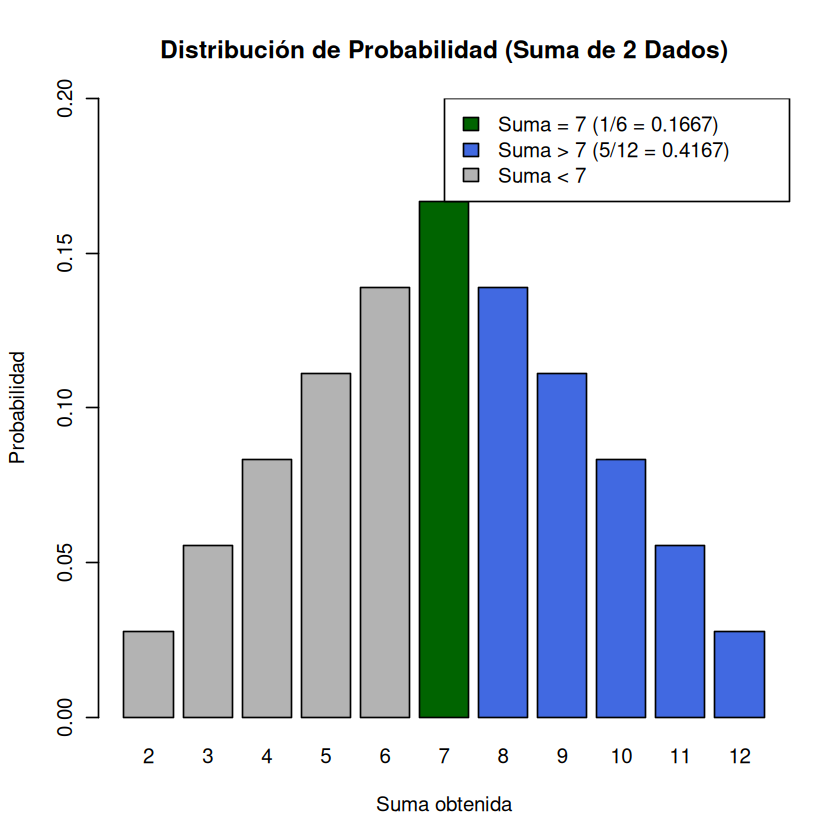

In [8]:
#Ejercicio 7
#Enunciado: Se lanzan dos dados y se suman los puntos obtenidos.
  
#¿Cuál es la probabilidad de obtener 7 puntos?
  
#¿Cuál es la probabilidad de obtener más de 7 puntos?

library(MASS)

# 1. Crear el espacio muestral de dos dados (36 casos posibles)
dado1 <- 1:6
dado2 <- 1:6
espacio_muestral <- expand.grid(d1 = dado1, d2 = dado2)
espacio_muestral$suma <- espacio_muestral$d1 + espacio_muestral$d2

totales <- nrow(espacio_muestral) # 36

# 2. Conteo de casos favorables
fav_7 <- sum(espacio_muestral$suma == 7)
fav_mayor_7 <- sum(espacio_muestral$suma > 7)

# 3. Cálculos de probabilidad
p_7 <- fav_7 / totales
p_mayor_7 <- fav_mayor_7 / totales

# 4. Tabla de resultados con Fracción y Decimal
resultados <- data.frame(
  Ejercicio = c("Punto 1 (Suma = 7)", "Punto 2 (Suma > 7)"),
  Fraccion = as.character(fractions(c(p_7, p_mayor_7))),
  Decimal = round(c(p_7, p_mayor_7), 4)
)

print(resultados)

# 5. Generación del gráfico de barras
frecuencias <- table(espacio_muestral$suma)
colores <- ifelse(names(frecuencias) == "7", "darkgreen", 
           ifelse(as.numeric(names(frecuencias)) > 7, "royalblue", "gray70"))

barplot(frecuencias / totales, 
        main = "Distribución de Probabilidad (Suma de 2 Dados)",
        xlab = "Suma obtenida", 
        ylab = "Probabilidad",
        col = colores,
        ylim = c(0, 0.2))

legend("topright", 
       legend = c("Suma = 7 (1/6 = 0.1667)", "Suma > 7 (5/12 = 0.4167)", "Suma < 7"),
       fill = c("darkgreen", "royalblue", "gray70"))


                Punto Fraccion Decimal
1 Punto 1 (Suma = 10)      1/8   0.125
2 Punto 2 (Suma > 10)      1/2   0.500


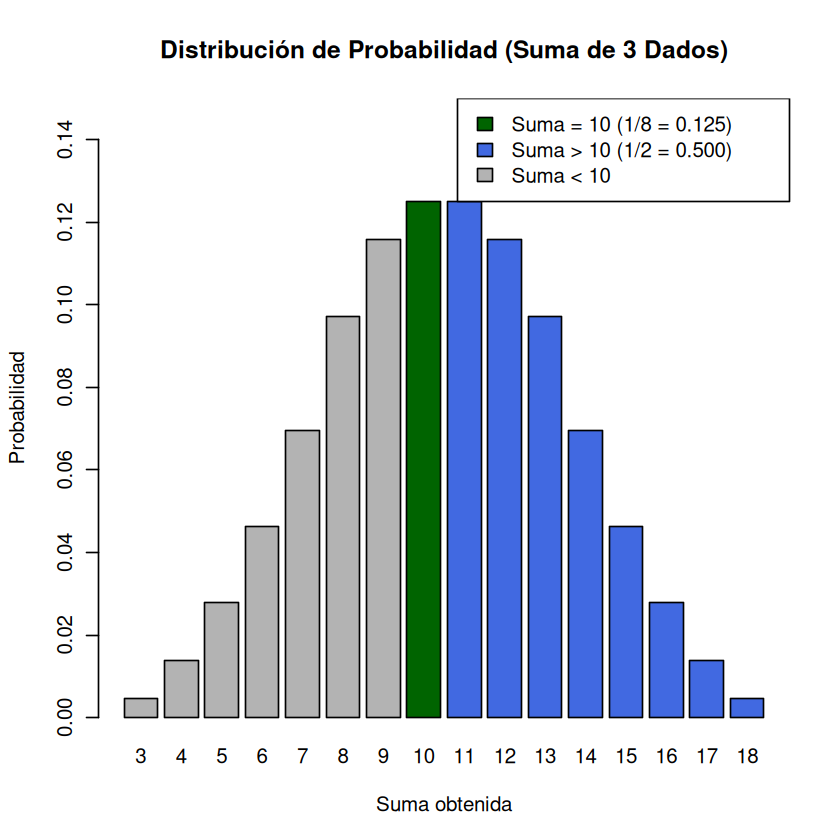

In [9]:
#Ejercicio 8
#Enunciado: Se lanzan tres dados y se suman los puntos obtenidos.
  
#¿Cuál es la probabilidad de obtener 10 puntos?
  
#¿Cuál es la probabilidad de obtener más de 10 puntos?
  
#¿Es justo jugar a la par, a que la suma pase de 10 que a que no pase? (Juego del siglo XVIII llamado "pase de diez")

library(MASS)

# 1. Espacio muestral de 3 dados (216 resultados)
dados <- expand.grid(d1 = 1:6, d2 = 1:6, d3 = 1:6)
dados$suma <- dados$d1 + dados$d2 + dados$d3

totales <- nrow(dados) # 216

# 2. Casos favorables
fav_10 <- sum(dados$suma == 10)
fav_mayor_10 <- sum(dados$suma > 10)

p_10 <- fav_10 / totales
p_mayor_10 <- fav_mayor_10 / totales

# 3. Mostrar resultados en tabla
res8 <- data.frame(
  Punto = c("Punto 1 (Suma = 10)", "Punto 2 (Suma > 10)"),
  Fraccion = as.character(fractions(c(p_10, p_mayor_10))),
  Decimal = round(c(p_10, p_mayor_10), 4)
)

print(res8)

# 4. Gráfico de la distribución de 3 dados
frecuencias <- table(dados$suma)
colores <- ifelse(names(frecuencias) == "10", "darkgreen",
           ifelse(as.numeric(names(frecuencias)) > 10, "royalblue", "gray70"))

barplot(frecuencias / totales,
        main = "Distribución de Probabilidad (Suma de 3 Dados)",
        xlab = "Suma obtenida",
        ylab = "Probabilidad",
        col = colores,
        ylim = c(0, 0.15))

legend("topright",
       legend = c("Suma = 10 (1/8 = 0.125)", "Suma > 10 (1/2 = 0.500)", "Suma < 10"),
       fill = c("darkgreen", "royalblue", "gray70"))


         Métrica Fracción Decimal
1       P(k > 2)      1/4   0.250
2 Esperanza E[K]     15/8   1.875

--- Resultados Simulados (N = 1e+05 ) ---
P(k > 2) simulada: 0.24872 
Promedio de lanzamientos E[K]: 1.87268 


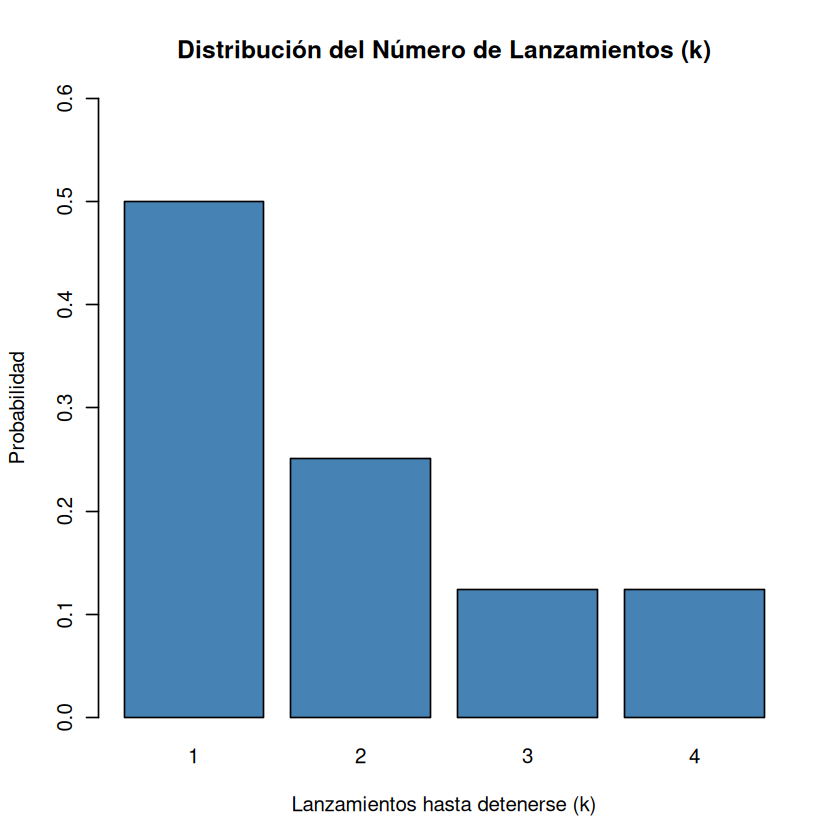

In [1]:
#Ejercicio 9
#Enunciado: Un jugador lanza una moneda hasta que sale cara o hasta haberla lanzado 4 veces.
#Hallar la probabilidad de que el juego termine en el k-ésimo lanzamiento (k = 1, 2, 3, 4).
#Hallar la probabilidad de que la moneda sea lanzada más de 2 veces.
#Hallar el número esperado de lanzamientos.

library(MASS)

# 1. Probabilidades teóricas
k_vals <- 1:4
p_k <- c(1/2, 1/4, 1/8, 1/8)

# Esperanza matemática teórica
esperanza_teorica <- sum(k_vals * p_k)
p_mayor_2_teorica <- sum(p_k[k_vals > 2])

# Mostrar tabla de teoría
df_teoria <- data.frame(
  Métrica = c("P(k > 2)", "Esperanza E[K]"),
  Fracción = as.character(fractions(c(p_mayor_2_teorica, esperanza_teorica))),
  Decimal = c(p_mayor_2_teorica, esperanza_teorica)
)
print(df_teoria)

# 2. Simulación de Monte Carlo
N <- 100000
lanzamientos <- numeric(N)

set.seed(42)
for (i in 1:N) {
  tiros <- 0
  exito <- FALSE
  while (tiros < 4 && !exito) {
    tiros <- tiros + 1
    if (sample(c("C", "X"), 1) == "C") {
      exito <- TRUE
    }
  }
  lanzamientos[i] <- tiros
}

# Resultados simulados
cat("\n--- Resultados Simulados (N =", N, ") ---\n")
cat("P(k > 2) simulada:", mean(lanzamientos > 2), "\n")
cat("Promedio de lanzamientos E[K]:", mean(lanzamientos), "\n")

# Gráfico de barras
frec_sim <- prop.table(table(lanzamientos))
barplot(frec_sim, 
        main = "Distribución del Número de Lanzamientos (k)",
        xlab = "Lanzamientos hasta detenerse (k)",
        ylab = "Probabilidad",
        col = "steelblue",
        ylim = c(0, 0.6))


In [2]:
# Ejercicio 10
# Probabilidad de que 3 cajas queden ocupadas con 6 bolas
p_ej10 <- (3^6 - 3 * (2^6) + 3 * (1^6)) / (3^6)
p_ej10


[1] 0.7407407

In [3]:
# Ejercicio 11
# Función para r rojas, w blancas
p_ej11 <- function(r, w) { w / (r + w) }
